# 01 · Vectors and cosine similarity

Maths unit **M1**. Read `vision/encoders.py` (L2 normalisation) and `search/index.py` first.

Every image in VisualTaste is two vectors: 768 numbers from **SigLIP 2**, trained to match images with captions, and 768 from **DINOv2**, trained on images alone. Every model in the project, from Rocchio to the neural ranker, works on these vectors, and the basic question they all ask is how close two images are. This notebook answers it three ways: by hand, on the stored vectors, and by looking at neighbours.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from visualtaste.api.deps import AppState
from visualtaste.config import get_settings
from visualtaste.vision.encoders import l2_normalise

settings = get_settings()
state = AppState(settings)
state.load()
features = state.features
siglip, dino = features.siglip, features.dinov2
print(f"{len(features):,} selected images; SigLIP {siglip.shape}, DINOv2 {dino.shape}")

Archive ladder reached rule 5: no external drive and only 35.9 GB free. Using the internal fallback by prior decision (docs/DECISIONS.md #2).


50,000 selected images; SigLIP (50000, 768), DINOv2 (50000, 768)


## 1 · M1 by hand

Cosine similarity is the angle between two vectors, ignoring their length:

$$\cos(a, b) = \frac{a \cdot b}{\lVert a \rVert \, \lVert b \rVert}$$

For A = (1, 2, 2) and B = (2, 1, 2): A·B = 2 + 2 + 4 = 8, and both lengths are 3, so cos = 8/9 ≈ 0.889. `tests/test_encoders.py` asserts exactly this.

In [2]:
A, B = np.array([1.0, 2.0, 2.0]), np.array([2.0, 1.0, 2.0])
by_formula = A @ B / (np.linalg.norm(A) * np.linalg.norm(B))
a_hat, b_hat = l2_normalise(np.stack([A, B]))
print(f"formula: {by_formula:.6f}   after normalising, a plain dot product: {a_hat @ b_hat:.6f}   8/9 = {8/9:.6f}")

formula: 0.888889   after normalising, a plain dot product: 0.888889   8/9 = 0.888889


## 2 · Why the stored vectors make cosine cheap

The embedding job normalises every vector to length 1 before saving it (`verify_normalised` checks it after every merge). Then the denominator is 1, cosine **is** the dot product, and similarity against the whole pool is one matrix-vector product: 50,000 dot products in a few milliseconds.

In [3]:
for name, vectors in (("SigLIP 2", siglip), ("DINOv2", dino)):
    norms = np.linalg.norm(vectors, axis=1)
    print(f"{name}: norms between {norms.min():.6f} and {norms.max():.6f}")

import time
query = siglip[0]
start = time.perf_counter()
scores = siglip @ query
print(f"cosine against all {len(scores):,} images: {1000 * (time.perf_counter() - start):.1f} ms")

SigLIP 2: norms between 0.999736 and 1.000258
DINOv2: norms between 0.999950 and 1.000059


cosine against all 50,000 images: 13.7 ms


## 3 · Neighbours in two spaces

The same query, its six nearest neighbours by SigLIP 2 (top row of each pair) and by DINOv2 (bottom row). SigLIP was trained to agree with captions, so it groups images by **what they show**. DINOv2 never saw text, so it groups them by **how they look**: texture, colour, composition. Simulator scenario S1 plants interests in SigLIP space and S2 in DINOv2 space for exactly this reason.

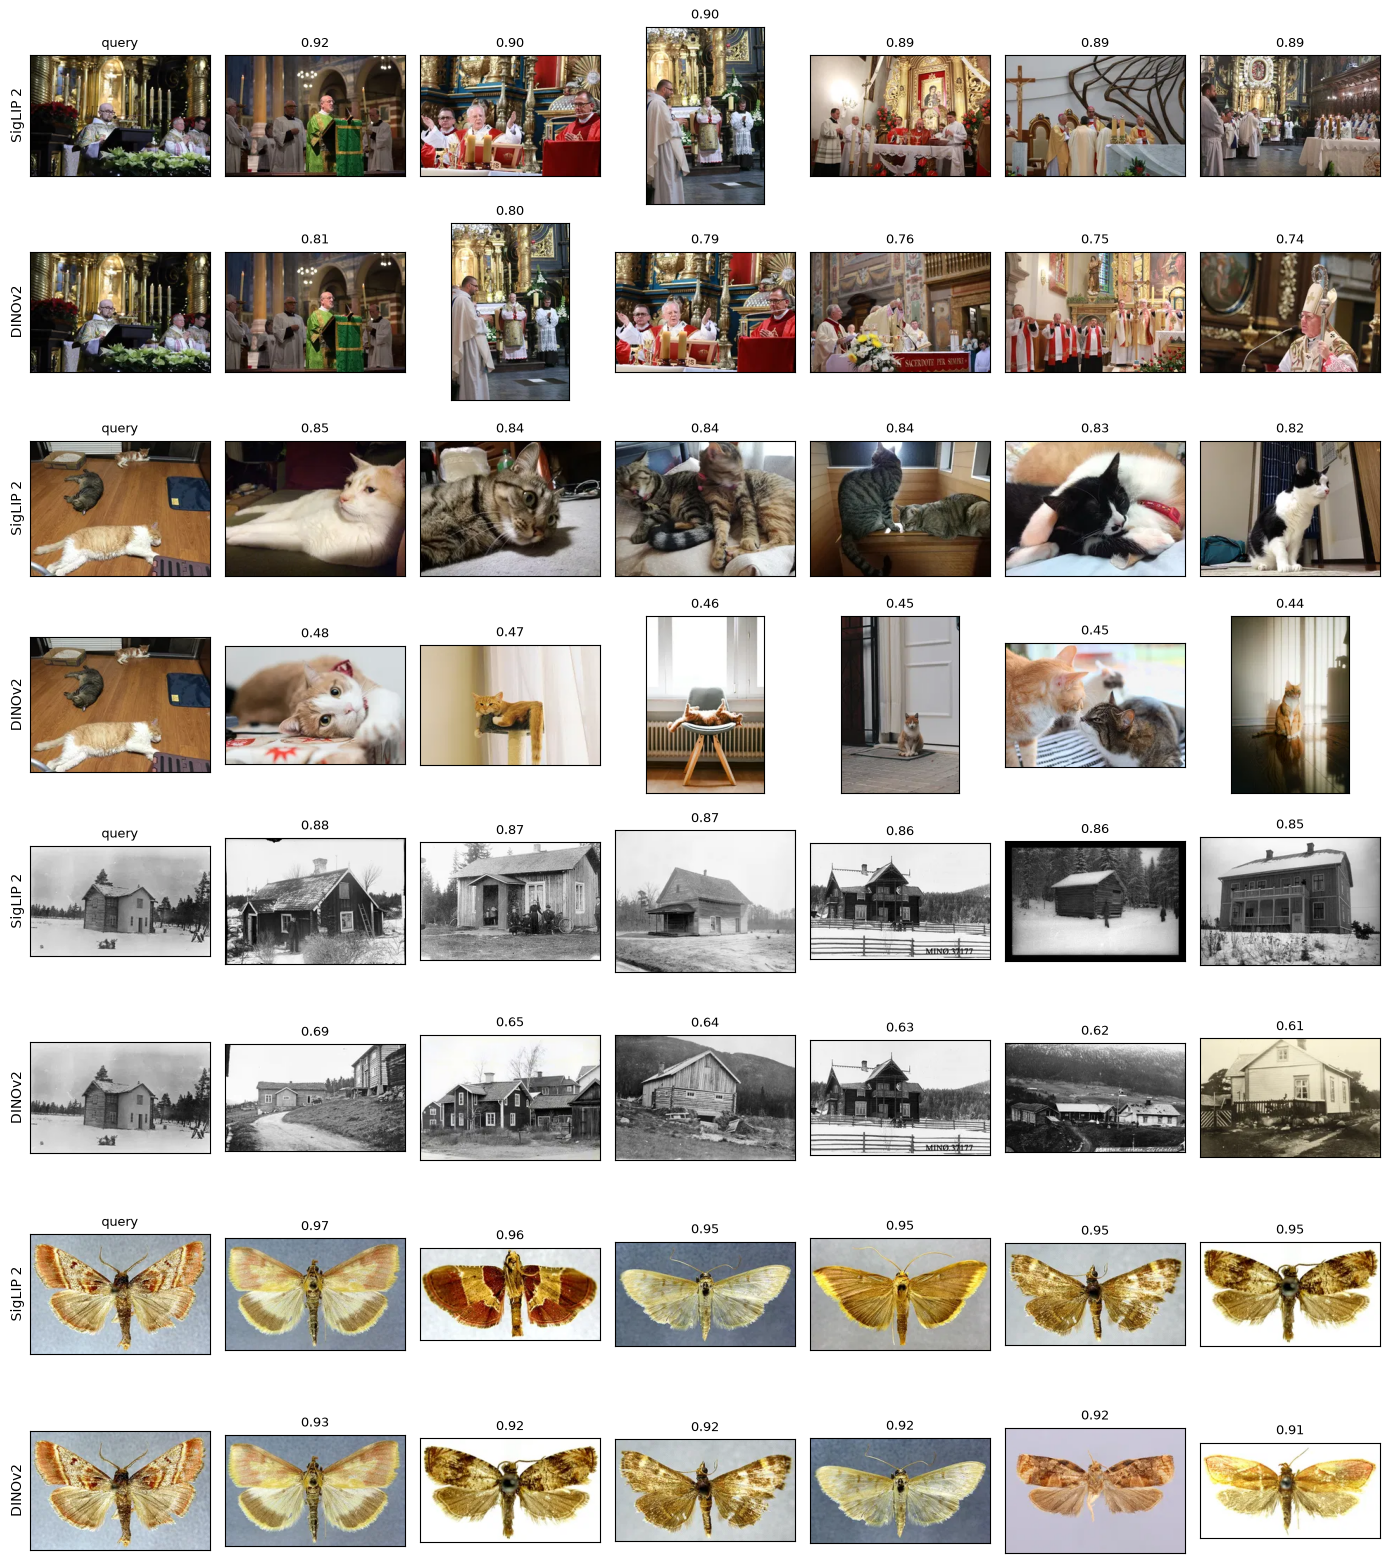

In [4]:
def thumb(row):
    image_id = features.image_ids[row]
    return Image.open(settings.thumb_path(image_id)).convert("RGB")

def neighbours(vectors, row, k=6):
    scores = vectors @ vectors[row]
    scores[row] = -np.inf
    top = np.argpartition(-scores, k)[:k]
    return top[np.argsort(-scores[top])], scores

rng = np.random.default_rng(1729)
queries = rng.choice(len(features), 4, replace=False)

fig, axes = plt.subplots(8, 7, figsize=(14, 16))
for q, row in enumerate(queries):
    for m, (name, vectors) in enumerate((("SigLIP 2", siglip), ("DINOv2", dino))):
        line = axes[2 * q + m]
        top, scores = neighbours(vectors, row)
        line[0].imshow(thumb(row))
        line[0].set_title("query" if m == 0 else "", fontsize=9)
        line[0].set_ylabel(name, fontsize=10)
        for j, n in enumerate(top, start=1):
            line[j].imshow(thumb(n))
            line[j].set_title(f"{scores[n]:.2f}", fontsize=9)
        for ax in line:
            ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

## 4 · How often do the two models agree?

For 300 random queries: of the ten nearest neighbours in SigLIP space, how many are also among the ten nearest in DINOv2 space?

mean overlap of the top 10: 2.77 images (median 2; 13% of queries share none)


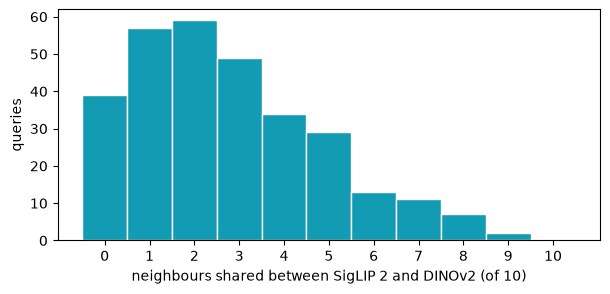

In [5]:
def top_k(vectors, row, k=10):
    scores = vectors @ vectors[row]
    scores[row] = -np.inf
    return set(np.argpartition(-scores, k)[:k].tolist())

sample = rng.choice(len(features), 300, replace=False)
overlap = np.array([len(top_k(siglip, r) & top_k(dino, r)) for r in sample])
print(f"mean overlap of the top 10: {overlap.mean():.2f} images "
      f"(median {np.median(overlap):.0f}; {np.mean(overlap == 0):.0%} of queries share none)")

plt.figure(figsize=(7, 3))
plt.hist(overlap, bins=np.arange(12) - 0.5, color="#139bb4", edgecolor="white")
plt.xlabel("neighbours shared between SigLIP 2 and DINOv2 (of 10)")
plt.ylabel("queries")
plt.xticks(range(11))
plt.show()

## What to take away

- **Normalised vectors make cosine a dot product.** Every stored vector has length 1 to within 3 × 10⁻⁴, so one matrix-vector product scores the whole pool (13.7 ms here for 50,000 images, on a busy CPU).
- **The two models see different things.** The grids show it: for the cats, SigLIP 2 keeps the subject (cats lying down), while DINOv2 keeps the light and the colour (a ginger cat in a bright room). For the snowy house, SigLIP finds more snowy wooden houses and DINOv2 more black-and-white village views. Only on very uniform images, like the museum moth specimens, do they nearly agree.
- **Measured, the overlap is small.** On average 2.8 of the ten nearest neighbours are shared, and 13% of queries share none. Two views, not one view twice, which is why R3 uses both blocks, and why adding DINOv2 helped most when the planted taste was about appearance (S2, `phase9_ablation`).
- **Scores are not comparable across models.** The same cat neighbours score about 0.84 in SigLIP space and 0.46 in DINOv2 space. Compare ranks within a model, never raw values across models; R3 standardises each block for the same reason (`rec/features.py`).

Next: `02_rocchio_and_knn`, which turns these similarities into a first taste model.